In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


In [43]:
df=pd.read_csv("../dataset/algerian cleaned dataset copy")

In [44]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0
2,31,67,14,0.0,82.6,5.8,22.2,3.1,7.0,2.5,1,0
3,33,54,13,0.0,88.2,9.9,30.5,6.4,10.9,7.2,1,0
4,30,73,15,0.0,86.6,12.1,38.3,5.6,13.5,7.1,1,0


In [45]:
 df.columns

Index(['Temperature', 'RH', 'Ws', 'Rain', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI',
       'FWI', 'Classes', 'Region'],
      dtype='object')

In [46]:
df["Classes"].value_counts()

Classes
1    109
0     46
Name: count, dtype: int64

In [47]:
X=df.drop("FWI",axis=1)
y=df["FWI"]

In [48]:
X.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0,0
1,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0,0
2,31,67,14,0.0,82.6,5.8,22.2,3.1,7.0,1,0
3,33,54,13,0.0,88.2,9.9,30.5,6.4,10.9,1,0
4,30,73,15,0.0,86.6,12.1,38.3,5.6,13.5,1,0


In [49]:
y

0       0.5
1       0.5
2       2.5
3       7.2
4       7.1
       ... 
150    15.2
151     3.0
152     6.5
153     0.7
154     0.5
Name: FWI, Length: 155, dtype: float64

In [50]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [51]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((116, 11), (39, 11), (116,), (39,))

In [52]:
X_train.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
Temperature,1.000000,-0.559001,-0.230201,0.183374,0.566862,0.463285,0.283647,0.461492,0.417772,0.420043,0.204674
RH,-0.559001,1.000000,0.199908,-0.244660,-0.537797,-0.234623,-0.009107,-0.597983,-0.157644,-0.324815,-0.367855
Ws,-0.230201,0.199908,1.000000,-0.033244,-0.107710,0.043008,0.198171,0.097889,0.107627,0.008749,-0.122995
Rain,0.183374,-0.244660,-0.033244,1.000000,-0.314503,-0.125594,-0.055046,-0.342224,-0.109802,-0.231680,0.045237
FFMC,0.566862,-0.537797,-0.107710,-0.314503,1.000000,0.599989,0.346243,0.848717,0.537716,0.803041,0.223466
DMC,0.463285,-0.234623,0.043008,-0.125594,0.599989,1.000000,0.784120,0.585579,0.967222,0.529022,0.197818
DC,0.283647,-0.009107,0.198171,-0.055046,0.346243,0.784120,1.000000,0.330981,0.912315,0.386790,-0.198952
ISI,0.461492,-0.597983,0.097889,-0.342224,0.848717,0.585579,0.330981,1.000000,0.522311,0.661965,0.259740
BUI,0.417772,-0.157644,0.107627,-0.109802,0.537716,0.967222,0.912315,0.522311,1.000000,0.502851,0.037944
Classes,0.420043,-0.324815,0.008749,-0.231680,0.803041,0.529022,0.386790,0.661965,0.502851,1.000000,0.173053


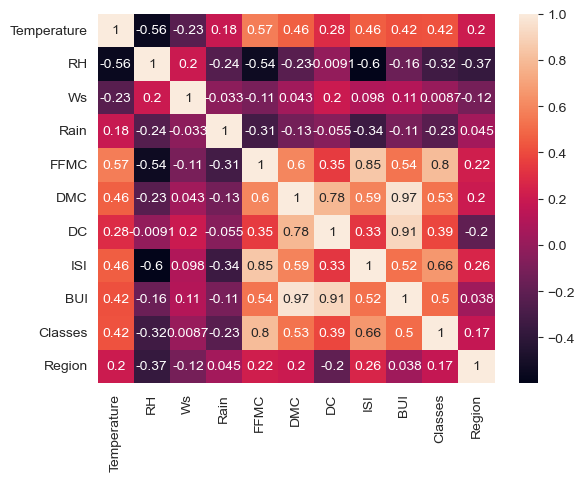

In [53]:
sns.heatmap(X_train.corr(),annot=True)
plt.show()

In [54]:
def correlation(dataset,threshold):
    col_corr=set()
    corr_matrix=dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i,j]) > threshold:
                colname=corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr


In [55]:
corr_features=correlation(X_train,0.85)

In [56]:
X_train.drop(corr_features,axis=1,inplace=True)
X_test.drop(corr_features,axis=1,inplace=True)
X_test.shape,X_train.shape

((39, 10), (116, 10))

Feature scaling and Standardization


In [57]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [58]:
X_train_scaled

array([[-6.22722138e-01, -3.42614593e-01, -1.83868015e+00, ...,
        -8.20690416e-04,  6.03908836e-01, -9.33256525e-01],
       [ 6.67202291e-01,  2.75958058e-01, -5.75787103e-02, ...,
         1.57846123e-01,  6.03908836e-01, -9.33256525e-01],
       [-1.59016546e+00,  1.43578178e+00,  3.87696649e-01, ...,
        -1.27015520e+00, -1.65587907e+00, -9.33256525e-01],
       ...,
       [-6.22722138e-01,  3.53279639e-01,  1.27824737e+00, ...,
         4.11713026e-01,  6.03908836e-01, -9.33256525e-01],
       [-3.00241031e-01, -3.42614593e-01, -5.02854070e-01, ...,
        -1.27754141e-01,  6.03908836e-01,  1.07151675e+00],
       [ 3.44721184e-01, -1.10649849e-01,  1.27824737e+00, ...,
         8.24246741e-01,  6.03908836e-01,  1.07151675e+00]])

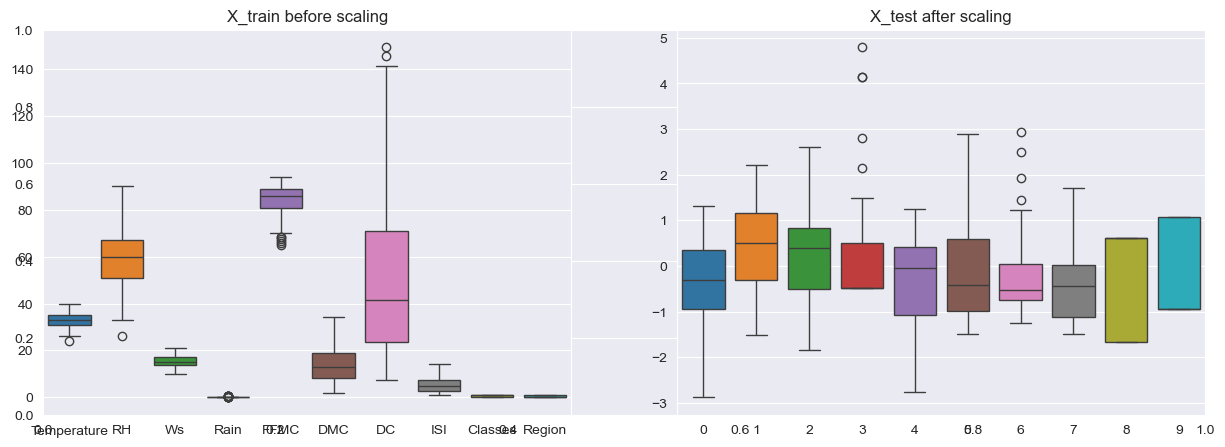

In [59]:
plt.subplots(figsize=(15,5))
plt.subplot(1,2,1)
sns.boxplot(X_train)
plt.title("X_train before scaling")
plt.subplot(1,2,2)
sns.boxplot(X_test_scaled)
plt.title("X_test after scaling")
plt.show()

linear regression model


In [60]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error

linear=LinearRegression()

mean absolute error = 0.3364732417442067
score = 0.9929793362992034


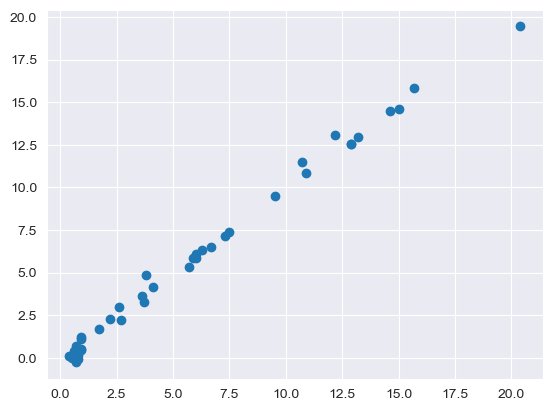

In [61]:
linear.fit(X_train_scaled,y_train)
y_pred=linear.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean absolute error =",mae)
print("score =",score)
plt.scatter(y_test,y_pred)
plt.show()

Mean absolute error 1.1173828703160074
R2 Score 0.9363090278449762


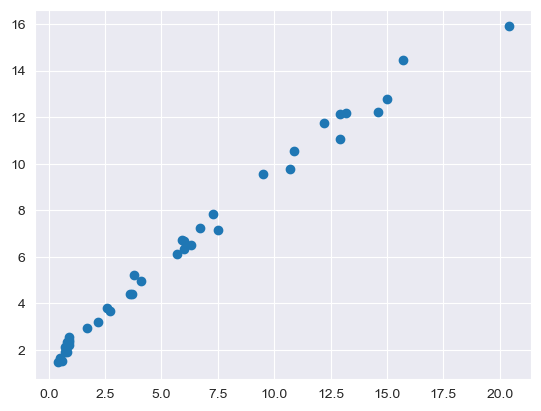

In [62]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
lasso=Lasso()
lasso.fit(X_train_scaled,y_train)
y_pred=lasso.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)
plt.show()

In [63]:
from sklearn.linear_model import LassoCV
lassocv=LassoCV(cv=5)
lassocv.fit(X_train_scaled,y_train)

LassoCV(cv=5)

In [64]:
y_pred=lassocv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)

Mean absolute error 0.3177971361946441
R2 Score 0.9931458281022731


Mean absolute error 0.348532862015634
R2 Score 0.9922563755600956


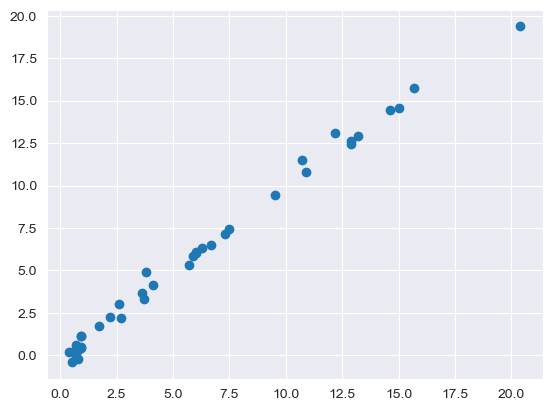

In [73]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
ridge=Ridge()
ridge.fit(X_train_scaled,y_train)
y_pred=ridge.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)
plt.show()

In [66]:
from sklearn.linear_model import RidgeCV
ridgecv=RidgeCV(cv=5)
ridgecv.fit(X_train_scaled,y_train)
y_pred=ridgecv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)

Mean absolute error 0.3371513905279143
R2 Score 0.9929336126210726


In [67]:
ridgecv.get_params()

{'alpha_per_target': False,
 'alphas': (0.1, 1.0, 10.0),
 'cv': 5,
 'fit_intercept': True,
 'gcv_mode': None,
 'scoring': None,
 'store_cv_results': None,
 'store_cv_values': 'deprecated'}

Mean absolute error 1.2855592182636701
R2 Score 0.9148820210071024


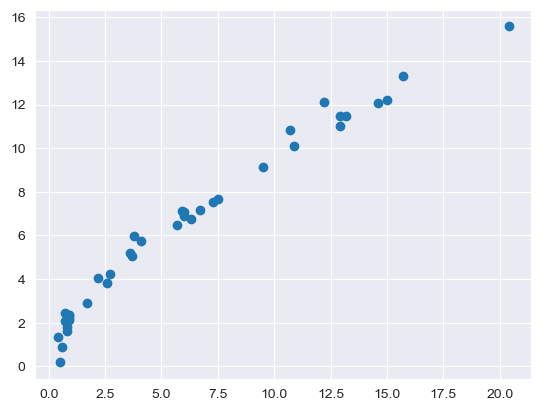

In [70]:
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
elastic=ElasticNet()
elastic.fit(X_train_scaled,y_train)
y_pred=elastic.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)
plt.show()

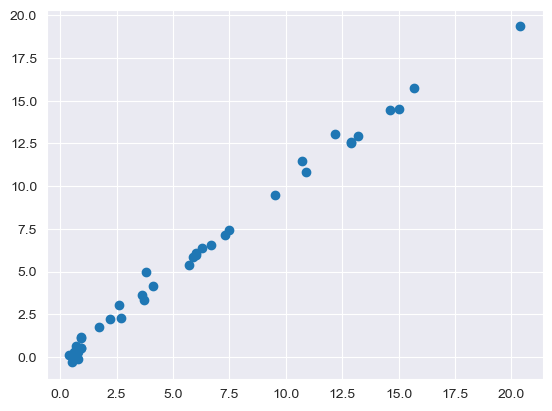

Mean absolute error 0.33794764943315014
R2 Score 0.9928265876458606


In [69]:
from sklearn.linear_model import ElasticNetCV
elasticcv=ElasticNetCV(cv=5)
elasticcv.fit(X_train_scaled,y_train)
y_pred=elasticcv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
plt.show()
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)


 ## Pickle the machine learning models,preprocessing model standard scaler


In [72]:
import pickle
pickle.dump(scaler,open("scaler.pkl","wb"))
pickle.dump(ridge,open("ridge.pkl","wb"))


In [ ]:
print(scaler.n_features_in_)
print(scaler.feature_names_in_)